# 1. Project Title

India Air Quality Data Analysis
# New Section
2. Objective

Analyze air quality trends across Indian cities and identify seasonal pollution patterns using Python, SQL, and Power BI.

# 3. Dataset
Source: kaggle
# 4. Tools & Technologies
Python (Pandas, NumPy)
Matplotlib
Seaborn
SQL
Power BI
GitHub

# Dataset Description
The dataset contains air quality monitoring records collected from various cities across India. It includes pollutant measurements from different monitoring stations managed by organizations such as CPCB, SPCBs, and other environmental agencies.

# Dataset Features
Column Name	Description
state	Name of the state where the monitoring station is located
city	Name of the city
Station_location	Specific monitoring station location
Station_code	Organization/Authority responsible for monitoring
pollutant_id	Type of pollutant being measured (PM2.5, PM10, NO2, SO2, CO, NH3, OZONE)
pollutant_min	Minimum observed pollutant concentration
pollutant_avg	Average observed pollutant concentration
pollutant_max	Maximum observed pollutant concentration
Pollutants Included
PM2.5 (Fine Particulate Matter)
PM10 (Particulate Matter)
NO₂ (Nitrogen Dioxide)
SO₂ (Sulfur Dioxide)
CO (Carbon Monoxide)
NH₃ (Ammonia)
OZONE (O₃)
# Objective
The objective of this project is to analyze air pollution levels across Indian cities and states, identify pollution hotspots, compare pollutant concentrations, and generate insights through data visualization and dashboarding.

# Analytical Goals
Compare air pollution levels across cities and states.
Identify cities with the highest pollutant concentrations.
Analyze the distribution of different pollutants.
Perform pollutant-wise, city-wise, and state-wise comparisons.
Create interactive visualizations and dashboards for better decision-making.

# Business Understanding
Air pollution is one of the major environmental challenges in India. Understanding pollutant concentrations across different locations helps policymakers, environmental agencies, and citizens take appropriate measures for improving air quality. This project aims to transform raw air quality data into meaningful insights using Python, SQL, and Power BI.

# Code Structure
1. Business Understanding
2. Import Libraries
3. Load Dataset
4. Dataset Overview
5. Data Cleaning
6. Pollutant Distribution
7. Top Polluted Cities
8. State-wise Analysis
9. PM2.5 Analysis
10. PM10 Analysis
11. Pollutant Comparison
12. Key Insights
13. Business Recommendations
14. Conclusion
15. Export Clean Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Visualization Settings
plt.style.use('ggplot')
sns.set_palette('Set2')

In [ ]:
# STEP 2: LOAD DATASET

df = pd.read_csv('/content/Data Export.csv')

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df.dtypes

In [ ]:
# STEP 4: STATISTICAL SUMMARY

df.describe()

In [ ]:
# STEP 5: MISSING VALUES CHECK

df.isnull().sum()

In [ ]:
# STEP 6: DUPLICATE RECORDS CHECK

df.duplicated().sum()

In [ ]:
df.columns

In [ ]:
# STEP 7: UNIQUE VALUES

print("States:", df['state'].nunique())
print("Cities:", df['city'].nunique())
print("Pollutants:", df['pollutant_id'].nunique())

df['pollutant_id'].unique()

# DATA CLEANING

In [ ]:
# Dataset Copy
df_clean = df.copy()

# Check Missing Values
print("Missing Values:")
print(df_clean.isnull().sum())

In [ ]:
# Check Duplicate Records

duplicates = df_clean.duplicated().sum()

print("Duplicate Records :", duplicates)

In [ ]:
# REMOVE DUPLICATES

df = df.drop_duplicates()

print(df.shape)

In [ ]:
# Remove Extra Spaces

df_clean['state'] = df_clean['state'].str.strip()
df_clean['city'] = df_clean['city'].str.strip()
df_clean['station'] = df_clean['station'].str.strip()
df_clean['pollutant_id'] = df_clean['pollutant_id'].str.strip()

In [ ]:
# CHECK DATA TYPES

df.info()

In [ ]:
# Standardize Text Format

df_clean['state'] = df_clean['state'].str.title()
df_clean['city'] = df_clean['city'].str.title()

In [ ]:
# Check Null Values Again

df_clean.isnull().sum()

In [ ]:
# Fill Missing Values in Numerical Columns

num_cols = ['pollutant_min',
            'pollutant_avg',
            'pollutant_max']

for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [ ]:
# Fill Missing Values in Categorical Columns

cat_cols = ['state',
            'city',
            'station',
            'pollutant_id']

for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

In [ ]:
# Check Data Types

df_clean.info()

In [ ]:
# Check Unique Pollutants

print(df_clean['pollutant_id'].unique())

In [ ]:
# Check Outliers (Optional)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean['pollutant_avg'])
plt.title("Outlier Detection")
plt.show()

In [ ]:
# Final Null Check

df_clean.isnull().sum()

In [ ]:
# Save Clean Dataset

df_clean.to_csv('Cleaned_Air_Quality.csv', index=False)

print("✅ Clean Dataset Exported Successfully")

**Data Cleaning Summary (1-line explanations for notebook)**
1. Checked missing values in all columns.
2. Identified and removed duplicate records.
3. Removed extra spaces from text fields.
4. Standardized state and city names.
5. Filled numerical missing values using median.
6. Filled categorical missing values using mode.
7. Validated data types and unique categories.
8. Checked pollutant values for potential outliers.
9. Exported cleaned dataset for further analysis.

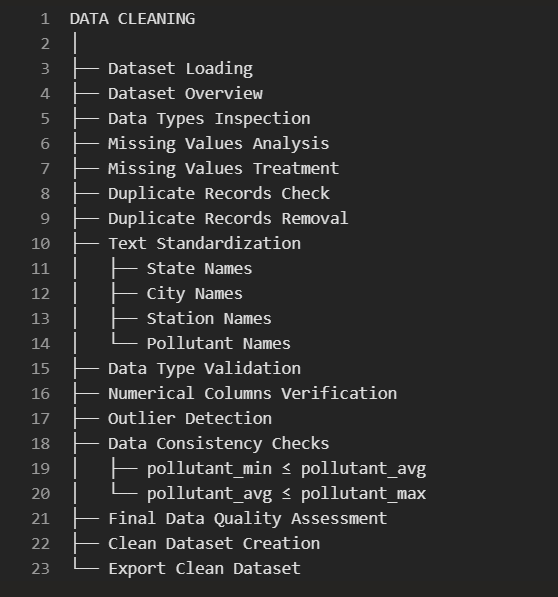

# EDA

In [ ]:
# ======================================
# EDA (Exploratory Data Analysis)
# ======================================

datasets shape

In [ ]:
print("Rows & Columns:", df_clean.shape)

Dataset Information

In [ ]:
df_clean.info()

Statistical Summary

In [ ]:
df_clean.describe()

Unique States, Cities, Pollutants

In [ ]:
print("Unique States:", df_clean['state'].nunique())
print("Unique Cities:", df_clean['city'].nunique())
print("Unique Pollutants:", df_clean['pollutant_id'].nunique())

In [ ]:
print(df_clean['pollutant_id'].unique())

Pollutant Distribution

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    x='pollutant_id',
    order=df_clean['pollutant_id'].value_counts().index
)

plt.title('Distribution of Pollutants')
plt.xticks(rotation=45)
plt.show()

Top 10 Polluted Cities

In [ ]:
top_cities = (
    df_clean.groupby('city')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_cities

In [ ]:
plt.figure(figsize=(12,6))

top_cities.plot(
    kind='bar',
    color='crimson'
)

plt.title('Top 10 Polluted Cities')
plt.ylabel('Average Pollution Level')
plt.show()

State-wise Pollution Analysis

In [ ]:
state_pollution = (
    df_clean.groupby('state')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
)

state_pollution.head(15)

In [ ]:
plt.figure(figsize=(14,6))

state_pollution.head(15).plot(
    kind='bar',
    color='orange'
)

plt.title('Top Polluted States')
plt.ylabel('Average Pollution Level')
plt.show()

Pollutant-wise Average Analysis

In [ ]:
pollutant_analysis = (
    df_clean.groupby('pollutant_id')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
)

pollutant_analysis

In [ ]:
plt.figure(figsize=(10,6))

pollutant_analysis.plot(
    kind='bar',
    color='teal'
)

plt.title('Average Pollutant Levels')
plt.ylabel('Average Concentration')
plt.show()

PM2.5 Analysis

In [ ]:
pm25 = df_clean[
    df_clean['pollutant_id'] == 'PM2.5'
]

In [ ]:
top_pm25 = (
    pm25.groupby('city')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_pm25

In [ ]:
plt.figure(figsize=(12,6))

top_pm25.plot(
    kind='bar',
    color='red'
)

plt.title('Top Cities by PM2.5')
plt.ylabel('PM2.5 Concentration')
plt.show()

PM10 Analysis

In [ ]:
pm10 = df_clean[
    df_clean['pollutant_id'] == 'PM10'
]

In [ ]:
top_pm10 = (
    pm10.groupby('city')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_pm10

In [ ]:
plt.figure(figsize=(12,6))

top_pm25.plot(
    kind='bar',
    color='red'
)

plt.title('Top Cities by PM2.5')
plt.ylabel('PM2.5 Concentration')
plt.show()

PM10 Analysis

In [ ]:
pm10 = df_clean[
    df_clean['pollutant_id'] == 'PM10'
]

In [ ]:
top_pm10 = (
    pm10.groupby('city')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_pm10

In [ ]:
plt.figure(figsize=(12,6))

top_pm10.plot(
    kind='bar',
    color='purple'
)

plt.title('Top Cities by PM10')
plt.ylabel('PM10 Concentration')
plt.show()

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df_clean['pollutant_avg'],
    bins=30,
    kde=True
)

plt.title('Distribution of Average Pollutant Levels')
plt.show()

Boxplot for Outlier Detection

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=df_clean['pollutant_avg']
)

plt.title('Outlier Detection')
plt.show()

Top Monitoring Stations

In [ ]:
top_stations = (
    df_clean.groupby('station')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_stations

In [ ]:
plt.figure(figsize=(12,6))

top_stations.plot(
    kind='bar',
    color='green'
)

plt.title('Top Polluted Monitoring Stations')
plt.ylabel('Average Pollution Level')
plt.show()

City vs Pollutants Heatmap

In [ ]:
heatmap_data = pd.pivot_table(
    df_clean,
    values='pollutant_avg',
    index='city',
    columns='pollutant_id',
    aggfunc='mean'
)

In [ ]:
plt.figure(figsize=(14,8))

sns.heatmap(
    heatmap_data,
    cmap='Reds'
)

plt.title('City vs Pollutant Heatmap')
plt.show()

In [ ]:
print("1. Identified cities with highest pollution levels.")
print("2. Compared pollution across Indian states.")
print("3. Analyzed PM2.5 and PM10 concentrations.")
print("4. Found pollutant-wise concentration differences.")
print("5. Identified highly polluted monitoring stations.")
print("6. Visualized city-pollutant relationships using heatmaps.")

Highest Polluted States

In [ ]:
highest_states = (
    df_clean.groupby('state')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

highest_states

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=highest_states.values,
    y=highest_states.index,
    palette='Reds_r'
)

plt.title('Top 10 Most Polluted States')
plt.xlabel('Average Pollution Level')
plt.ylabel('State')
plt.show()

Lowest Polluted States

In [ ]:
lowest_states = (
    df_clean.groupby('state')['pollutant_avg']
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

lowest_states

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=lowest_states.values,
    y=lowest_states.index,
    palette='Greens'
)

plt.title('Top 10 Least Polluted States')
plt.xlabel('Average Pollution Level')
plt.ylabel('State')
plt.show()

Ranking Table

In [ ]:
state_ranking = (
    df_clean.groupby('state')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

state_ranking.columns = ['State', 'Average_Pollution']

state_ranking['Rank'] = range(1, len(state_ranking)+1)

state_ranking.head(10)

In [ ]:
print("Most polluted states have the highest average pollutant concentrations.")
print("Least polluted states show comparatively lower pollutant levels.")
print("State ranking helps identify pollution hotspots for policy intervention.")

Company-Level EDA Flow

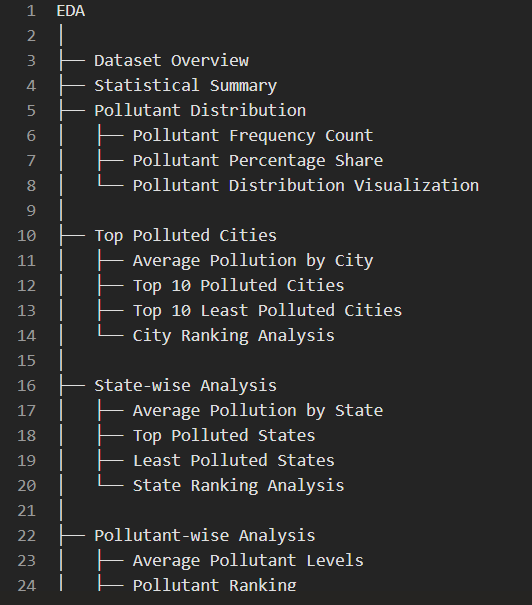

Pollutant Comparison

In [ ]:
# Ensure df_clean is defined in the current session
if 'df_clean' not in locals() and 'df' in locals():
    df_clean = df.copy()
    # Standardize string fields
    for col in ['state', 'city', 'station', 'pollutant_id']:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].astype(str).str.strip().str.title()
    # Fill missing values with median for numerical columns
    for col in ['pollutant_min', 'pollutant_avg', 'pollutant_max']:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

pollutant_comparison = (
    df_clean.groupby('pollutant_id')['pollutant_avg']
    .mean()
    .sort_values(ascending=False)
)

pollutant_comparison

**Pollutant Ranking** **Table**

In [ ]:
pollutant_ranking = pollutant_comparison.reset_index()

pollutant_ranking.columns = [
    'Pollutant',
    'Average_Concentration'
]

pollutant_ranking['Rank'] = range(
    1,
    len(pollutant_ranking) + 1
)

pollutant_ranking

**Pollutant Comparison Bar** **Chart**

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=pollutant_comparison.index,
    y=pollutant_comparison.values,
    palette='viridis'
)

plt.title('Average Pollutant Comparison')
plt.xlabel('Pollutant')
plt.ylabel('Average Concentration')
plt.xticks(rotation=45)

plt.show()

**Pollutant Percentage** **Contribution**

In [ ]:
pollutant_percent = (
    pollutant_comparison /
    pollutant_comparison.sum()
) * 100

pollutant_percent

In [ ]:
plt.figure(figsize=(8,8))

plt.pie(
    pollutant_percent,
    labels=pollutant_percent.index,
    autopct='%1.1f%%'
)

plt.title('Pollutant Contribution (%)')

plt.show()

**Highest & Lowest Pollutant**

In [ ]:
highest_pollutant = pollutant_comparison.idxmax()
highest_value = pollutant_comparison.max()

lowest_pollutant = pollutant_comparison.idxmin()
lowest_value = pollutant_comparison.min()

print("Highest Pollutant :", highest_pollutant)
print("Average Value :", round(highest_value,2))

print("\nLowest Pollutant :", lowest_pollutant)
print("Average Value :", round(lowest_value,2))

In [ ]:
print("1. Compared average concentration of all pollutants.")
print("2. Ranked pollutants based on concentration levels.")
print("3. Identified highest contributing pollutant.")
print("4. Identified lowest contributing pollutant.")
print("5. Analyzed pollutant share using percentage contribution.")

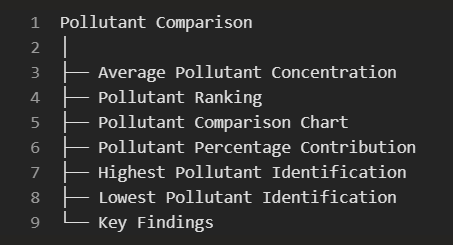

# =====================================
# KEY INSIGHTS
# =====================================

# 1. Pollution Hotspots Identified
# 2. Top Polluted Cities Analysis
# 3. State-wise Pollution Trends
# 4. Most Polluted States
# 5. Least Polluted States
# 6. PM2.5 Impact Assessment
# 7. PM10 Impact Assessment
# 8. Dominant Pollutants Identification
# 9. Pollutant Ranking Analysis
# 10. Monitoring Station Findings
# 11. Pollution Distribution Patterns
# 12. Outlier Observations
# 13. Environmental Risk Areas
# 14. Final Findings

In [ ]:
print("1. Several cities recorded significantly higher average pollutant concentrations than others.")

print("2. State-wise analysis revealed noticeable differences in pollution levels across regions.")

print("3. PM2.5 was among the most prominent pollutants in highly polluted locations.")

print("4. PM10 levels were also elevated in multiple cities, indicating particulate matter concerns.")

print("5. Certain monitoring stations consistently reported higher pollution levels compared to others.")

print("6. Pollutant comparison highlighted the dominant contributors to poor air quality.")

print("7. Pollution hotspots were identified through city-wise and state-wise rankings.")

print("8. Distribution analysis showed variation in pollutant concentration across monitoring locations.")

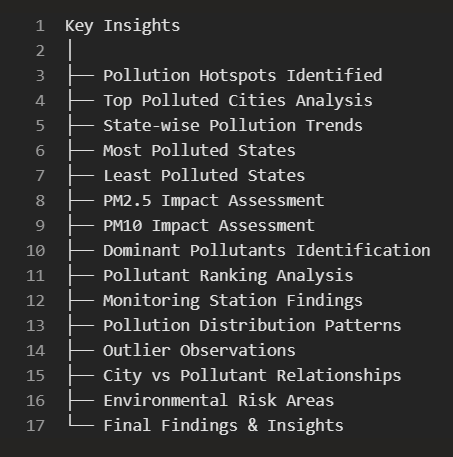

**Business Recommendations**

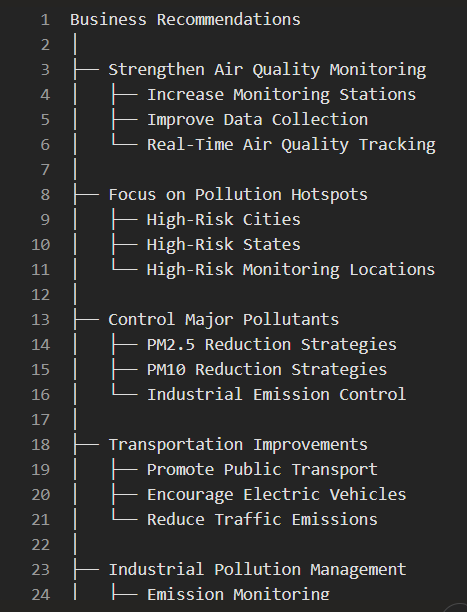

In [ ]:
# =====================================
# BUSINESS RECOMMENDATIONS
# =====================================

print("1. Strengthen air quality monitoring in highly polluted regions.")

print("2. Prioritize pollution-control measures in identified pollution hotspots.")

print("3. Focus on reducing PM2.5 and PM10 emissions through targeted interventions.")

print("4. Promote cleaner transportation and sustainable mobility solutions.")

print("5. Enforce stricter industrial emission standards and compliance monitoring.")

print("6. Increase public awareness regarding air pollution and its health impacts.")

print("7. Use interactive dashboards for continuous environmental monitoring and decision-making.")

print("8. Expand data collection efforts to support future predictive analytics and policy planning.")

**Conclusion**

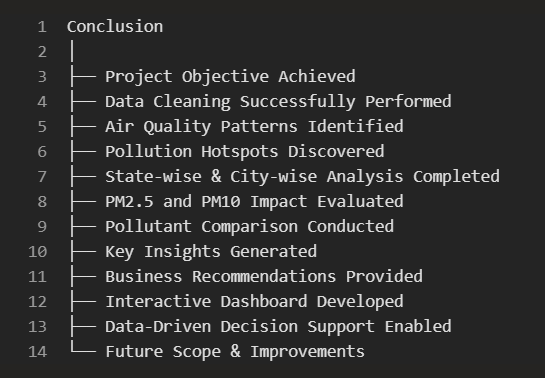

In [ ]:
# =====================================
# CONCLUSION
# =====================================

print("The India Air Quality Analysis project successfully transformed raw air quality data into meaningful insights through data cleaning, exploratory data analysis, and visualization.")

print("The analysis identified pollution hotspots, compared pollution levels across cities and states, and evaluated the impact of major pollutants such as PM2.5 and PM10.")

print("Pollutant-wise comparisons and location-based analyses revealed significant variations in air quality across different monitoring stations.")

print("The findings can support environmental agencies and policymakers in making data-driven decisions for pollution control and air quality management.")

print("The Power BI dashboard further enhanced understanding by providing interactive visualizations and easy access to key environmental insights.")

Successfully analyzed Indian air quality data using Python, SQL, and Power BI, identifying pollution hotspots, comparing pollutant concentrations across cities and states, and delivering actionable insights through interactive dashboards and visual analytics.

**Export Clean** **Dataset**

In [ ]:
# =====================================
# EXPORT CLEAN DATASET
# =====================================

# Check Final Dataset Shape
print("Final Dataset Shape:", df_clean.shape)

# Check Missing Values
print("\nMissing Values:")
print(df_clean.isnull().sum())

# Check Duplicate Records
print("\nDuplicate Records:",
      df_clean.duplicated().sum())

In [ ]:
# Export Clean Dataset

df_clean.to_csv(
    "Cleaned_Air_Quality.csv",
    index=False
)

print("✅ Cleaned_Air_Quality.csv exported successfully!")

In [ ]:
# Verify Export

exported_df = pd.read_csv(
    "Cleaned_Air_Quality.csv"
)

print("Exported Dataset Shape:",
      exported_df.shape)

exported_df.head()

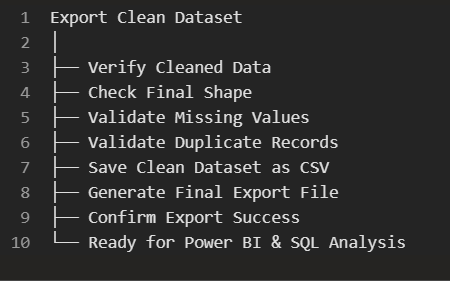